# **MÓDULO 27 - Projeto de Doenças Cardiovasculares - Regressão Logística**


Assim como na aula que trabalhamos com uma base de dados nova, com um contexto de modelo de propensão a compra de carros, para a atividade de vocês achei interessante trazer também novos desafios.

Nessa tarefa iremos construir um modelo que nos ajude a prever doenças cardiovasculares, a base contém dados reais.

age - idade dos pacientes

gender - genero (2 mulheres) (1 homens)

height - altura dos pacientes

weight - peso dos pacientes

gluc - glicose

smoke - fumante (1) não fumante (0)

alco - consume alcool (1) não consome (0)

active - realiza atividades fisicas (1) não realiza (0)

cardio_disease - tem doença cardio (1) não tem (0) - Variável target


Seu objetivo é utilizar esses dados históricos dos pacientes e construir um bom modelo de regressão capaz de indicar se novos pacientes estão propensos a doenças cariovasculares ou não.

In [15]:
import pandas as pd
import numpy as np
import seaborn as sns
import plotly.express as px
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy.stats import gaussian_kde
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score, classification_report
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import roc_curve, auc

# 1) Comece carregando e tratando a base de dados.
Assim como na aula essa nova base não passou por pré processamento nenhum então nessa etapa, carrega os dados, verifique os tipos de dados, verifique se temos dados faltantes e outliers.
Quando necessário realize o tratamento.


In [16]:
base = pd.read_csv(r"C:\Users\Rafael\Downloads\Cursos\Ebac\Curso de Ciencia de Dados\24 - Regressão Logística\CARDIO_BASE.csv", delimiter=';')

      age  gender  height weight  cholesterol  gluc  smoke  alco  active  cardio_disease
0      50       2     168     62            1     1      0     0       1               0
1      55       1     156     85            3     1      0     0       1               1
2      52       1     165     64            3     1      0     0       0               1
3      48       2     169     82            1     1      0     0       1               1
4      48       1     156     56            1     1      0     0       0               0
...   ...     ...     ...    ...          ...   ...    ...   ...     ...             ...
9995   56       1     166     65            1     1      0     0       0               0
9996   50       1     160     93            2     1      0     0       1               1
9997   40       1     158     66            2     2      0     0       1               0
9998   50       1     168     70            3     1      0     0       1               1
9999   54       2    

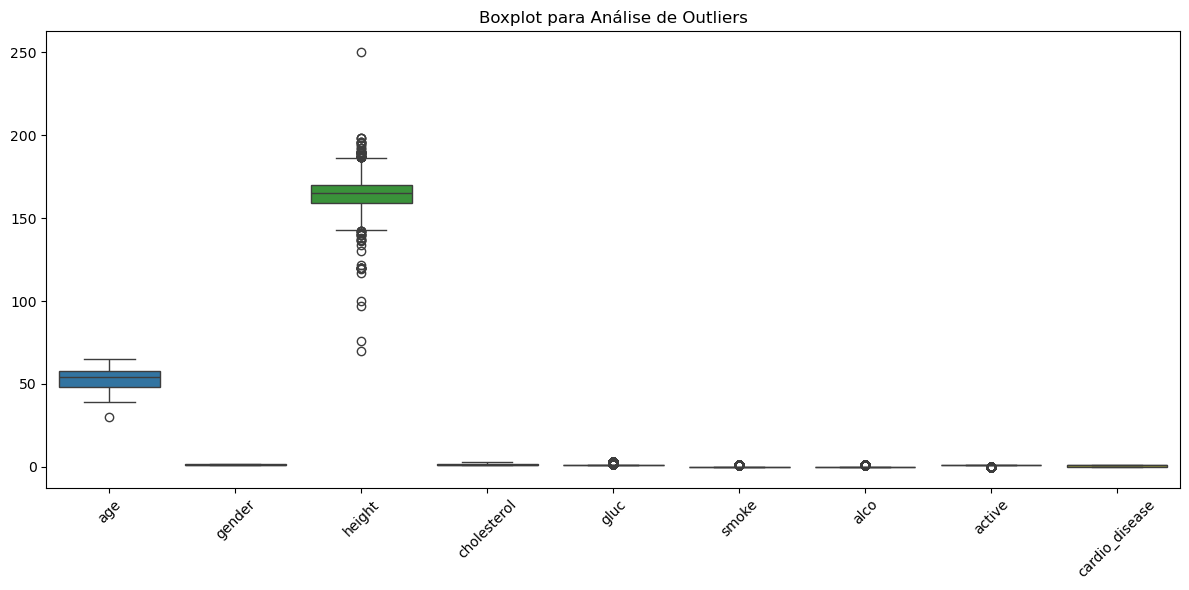


--- COMPARAÇÃO: MÉDIA VS MEDIANA (EFEITO DOS OUTLIERS) ---

Coluna: 'age' (1 outliers)
  Média com Outliers.......: 53.29
  Média sem Outliers.......: 53.29
  Mediana (Referência).....: 54.00

Coluna: 'gender' -> Sem outliers detectados (Média: 1.35 | Mediana: 1.00)

Coluna: 'height' (74 outliers)
  Média com Outliers.......: 164.31
  Média sem Outliers.......: 164.31
  Mediana (Referência).....: 165.00

Coluna: 'cholesterol' -> Sem outliers detectados (Média: 1.36 | Mediana: 1.00)

Coluna: 'gluc' (1487 outliers)
  Média com Outliers.......: 1.22
  Média sem Outliers.......: 1.00
  Mediana (Referência).....: 1.00

Coluna: 'smoke' (890 outliers)
  Média com Outliers.......: 0.09
  Média sem Outliers.......: 0.00
  Mediana (Referência).....: 0.00

Coluna: 'alco' (537 outliers)
  Média com Outliers.......: 0.05
  Média sem Outliers.......: 0.00
  Mediana (Referência).....: 0.00

Coluna: 'active' (2028 outliers)
  Média com Outliers.......: 0.80
  Média sem Outliers.......: 1.00
  Mediana

In [17]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print(base)

df = pd.DataFrame(base)
print("--- Usando dtypes ---")
print(df.dtypes)
print("\n--- Usando info() ---")
df.info()

print("\n--- Verificando a Porcentagem de Dados Faltantes e Nulos ---")
porcentagem_nulos = (df.isnull().mean() * 100).round(2)
print(porcentagem_nulos[porcentagem_nulos > 0])

print("\n--- VERIFICAÇÃO DE OUTLIERS (MÉTODO IQR) ---")
colunas_numericas = df.select_dtypes(include=[np.number]).columns

for coluna in colunas_numericas:
    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    
    outliers = df[(df[coluna] < limite_inferior) | (df[coluna] > limite_superior)]
    print(f"Coluna '{coluna}': {len(outliers)} outliers encontrados")

plt.figure(figsize=(12, 6))
sns.boxplot(data=df.select_dtypes(include=[np.number]))
plt.xticks(rotation=45)
plt.title('Boxplot para Análise de Outliers')
plt.tight_layout()
plt.show()

print("\n--- COMPARAÇÃO: MÉDIA VS MEDIANA (EFEITO DOS OUTLIERS) ---")
colunas_numericas = df.select_dtypes(include=[np.number]).columns

for coluna in colunas_numericas:
    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    
    serie_original = df[coluna].dropna()
    serie_sem_outliers = serie_original[(serie_original >= limite_inferior) & (serie_original <= limite_superior)]
    
    qtd_outliers = len(serie_original) - len(serie_sem_outliers)
    
    if qtd_outliers > 0:
        print(f"\nColuna: '{coluna}' ({qtd_outliers} outliers)")
        print(f"  Média com Outliers.......: {serie_original.mean():.2f}")
        print(f"  Média sem Outliers.......: {serie_sem_outliers.mean():.2f}")
        print(f"  Mediana (Referência).....: {serie_original.median():.2f}")
    else:
        print(f"\nColuna: '{coluna}' -> Sem outliers detectados (Média: {serie_original.mean():.2f} | Mediana: {serie_original.median():.2f})")

print("\n--- RELATÓRIO DE ANÁLISE DOS OUTLIERS ---")
print(
    "Durante a análise exploratória do conjunto de dados, foi realizada uma "
    "verificação estatística utilizando o método do Intervalo Interquartil (IQR) "
    "para identificar a presença de outliers (valores discrepantes), com o "
    "objetivo de avaliar se esses pontos poderiam comprometer os resultados "
    "futuros. Ao examinar as variáveis contínuas, como age (idade) e height "
    "(altura), constatou-se uma incidência muito baixa de valores discrepantes "
    "— apenas 1 registro em idade e 74 em altura — e percebeu-se que a média "
    "com e sem esses pontos permaneceu praticamente idêntica (53,29 para idade "
    "e 164,31 para altura), demonstrando que esses raros pontos isolados são "
    "estatisticamente irrelevantes diante do volume total de dados. Por outro "
    "lado, o método IQR apontou uma quantidade considerável de 'outliers' em "
    "colunas como gluc (glicose), smoke (tabagismo), alco (consumo de álcool) e "
    "active (atividade física), mas por serem variáveis de natureza binária "
    "(que trabalham apenas com os valores 0 ou 1) e terem a maioria da população "
    "concentrada em uma das respostas, o algoritmo acaba interpretando a minoria "
    "oposta como um ponto fora da curva, gerando falsos outliers que apenas "
    "refletem comportamentos reais e legítimos de uma parcela do grupo. Em "
    "conclusão, o diagnóstico mostra que os outliers encontrados não representam "
    "nenhum risco para o trabalho, seja pelo impacto estatístico nulo nas "
    "variáveis contínuas ou por representarem minorias reais nas variáveis "
    "binárias, permitindo seguir tranquilamente para as próximas etapas da "
    "análise ou modelagem sem a necessidade de remover esses registros."
)

# 2) Agora é hora de explorar os dados com uma análise bem completa.
Plote pelo menos 3 gráficos analisando o comportamento da variável cardio com outras variaveis da sua preferência (análise bivariada). Não se esqueça de trazer insights acerca do analisado.


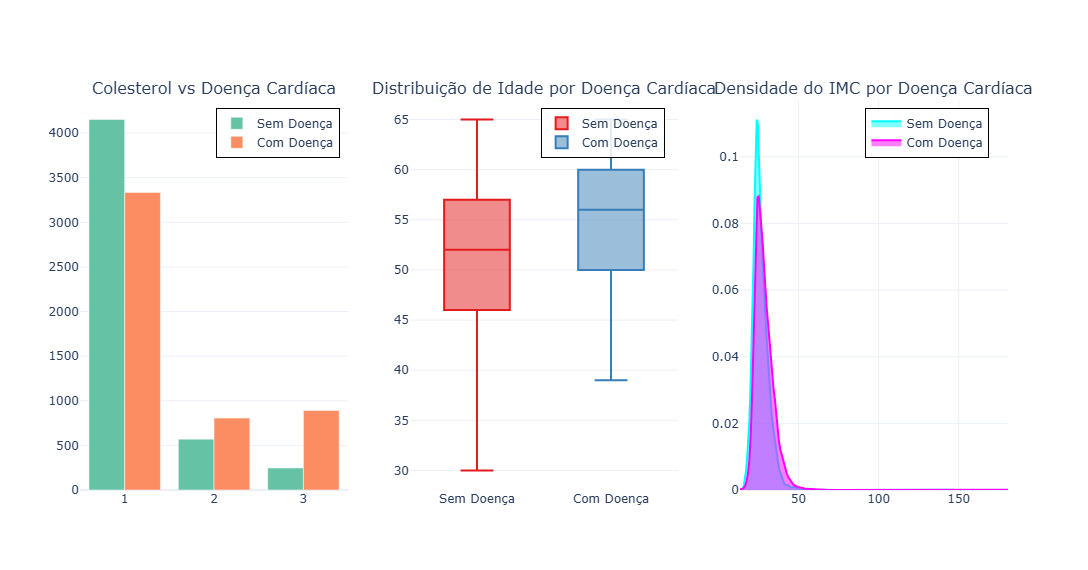

--- RELATÓRIO DE INSIGHTS: DASHBOARD BIVARIADO DE SAÚDE CARDIOVASCULAR ---

Durante a construção do painel bivariado de saúde cardiovascular, realizou-se a exploração visual e relacional de variáveis-chave em cruzamento com o diagnóstico de doença cardíaca. Ao examinar o primeiro painel, referente ao nível de colesterol, constatou-se uma grande concentração de pacientes no nível normal (categoria 1) sem a patologia; contudo, à medida que o colesterol avança para os níveis superiores (categorias 2 e 3), a proporção de indivíduos diagnosticados com doença cardíaca cresce de forma acentuada, evidenciando o colesterol elevado como um fator de risco direto e crítico. No segundo painel, focado na distribuição etária por meio de boxplots, observou-se que a mediana da idade do grupo acometido pela doença posiciona-se em um patamar superior e deslocado para faixas mais avançadas em comparação ao grupo saudável, confirmando a idade avançada como um elemento central de vulnerabilidade cardiovascu

In [18]:
colunas_para_converter = ['weight', 'height', 'age', 'cholesterol', 'cardio_disease']
for coluna in colunas_para_converter:
    if coluna in df.columns:
        if df[coluna].dtype == 'object':
            df[coluna] = pd.to_numeric(df[coluna].astype(str).str.replace(',', '.'), errors='coerce')
        else:
            df[coluna] = pd.to_numeric(df[coluna], errors='coerce')

if 'age' in df.columns:
    if df['age'].mean() > 200:
        df['age_years'] = (df['age'] / 365.25).astype(int)
    else:
        df['age_years'] = df['age']

if 'weight' in df.columns and 'height' in df.columns:
    df['bmi'] = df['weight'] / ((df['height'] / 100) ** 2)

df['cardio_label'] = df['cardio_disease'].map({0: 'Sem Doença', 1: 'Com Doença'})

fig = make_subplots(
    rows=1, cols=3, 
    subplot_titles=(
        'Colesterol vs Doença Cardíaca', 
        'Distribuição de Idade por Doença Cardíaca', 
        'Densidade do IMC por Doença Cardíaca'
    )
)

for label, color in [('Sem Doença', '#66c2a5'), ('Com Doença', '#fc8d62')]:
    sub_chol = df[df['cardio_label'] == label].groupby('cholesterol').size().reset_index(name='count')
    fig.add_trace(
        go.Bar(
            x=sub_chol['cholesterol'], 
            y=sub_chol['count'], 
            name=label, 
            marker_color=color,
            legend='legend',
            showlegend=True
        ),
        row=1, col=1
    )

for label, color in [('Sem Doença', '#e41a1c'), ('Com Doença', '#377eb8')]:
    sub_age = df[df['cardio_label'] == label]
    fig.add_trace(
        go.Box(
            y=sub_age['age_years'], 
            name=label, 
            marker_color=color,
            legend='legend2',
            showlegend=True
        ),
        row=1, col=2
    )

for label, color in [('Sem Doença', '#00ffff'), ('Com Doença', '#ff00ff')]:
    sub_bmi = df[df['cardio_label'] == label]['bmi'].dropna()
    kde_x = np.linspace(sub_bmi.min(), sub_bmi.max(), 200)
    kde = gaussian_kde(sub_bmi)
    kde_y = kde(kde_x)
    
    fig.add_trace(
        go.Scatter(
            x=kde_x, 
            y=kde_y, 
            mode='lines', 
            name=label, 
            fill='tozeroy', 
            line=dict(color=color),
            legend='legend3',
            showlegend=True
        ),
        row=1, col=3
    )

fig.update_layout(
    barmode='group', 
    template='plotly_white', 
    height=550, 
    width=1300,
    legend=dict(x=0.28, y=0.98, xanchor='right', yanchor='top', bgcolor='rgba(255,255,255,0.85)', bordercolor='black', borderwidth=1),
    legend2=dict(x=0.63, y=0.98, xanchor='right', yanchor='top', bgcolor='rgba(255,255,255,0.85)', bordercolor='black', borderwidth=1),
    legend3=dict(x=0.98, y=0.98, xanchor='right', yanchor='top', bgcolor='rgba(255,255,255,0.85)', bordercolor='black', borderwidth=1)
)

fig.show()
print(
    "--- RELATÓRIO DE INSIGHTS: DASHBOARD BIVARIADO DE SAÚDE CARDIOVASCULAR ---\n\n"
    "Durante a construção do painel bivariado de saúde cardiovascular, realizou-se "
    "a exploração visual e relacional de variáveis-chave em cruzamento com o "
    "diagnóstico de doença cardíaca. Ao examinar o primeiro painel, referente ao "
    "nível de colesterol, constatou-se uma grande concentração de pacientes no "
    "nível normal (categoria 1) sem a patologia; contudo, à medida que o colesterol "
    "avança para os níveis superiores (categorias 2 e 3), a proporção de indivíduos "
    "diagnosticados com doença cardíaca cresce de forma acentuada, evidenciando o "
    "colesterol elevado como um fator de risco direto e crítico. No segundo painel, "
    "focado na distribuição etária por meio de boxplots, observou-se que a mediana "
    "da idade do grupo acometido pela doença posiciona-se em um patamar superior "
    "e deslocado para faixas mais avançadas em comparação ao grupo saudável, "
    "confirmando a idade avançada como um elemento central de vulnerabilidade "
    "cardiovascular. Por fim, a análise da densidade do Índice de Massa Corporal "
    "(IMC) no terceiro painel revelou uma sobreposição considerável entre as "
    "curvas centrais de ambos os grupos, embora o perfil com doença cardíaca "
    "apresente um sutil deslocamento e extensão em direção a valores mais elevados "
    "de IMC, reforçando a importância do controle ponderal no estilo de vida. "
    "Em suma, o dashboard bivariado sintetiza com clareza o impacto de fatores "
    "como colesterol, idade e peso sobre o risco cardíaco, fornecendo uma base "
    "analítica sólida para as etapas subsequentes do projeto."
)

# 3) Nessa etapa você deve trazer a matriz de correlação e apontar insights acerca das variáveis com um relacionamento mais forte entre si.



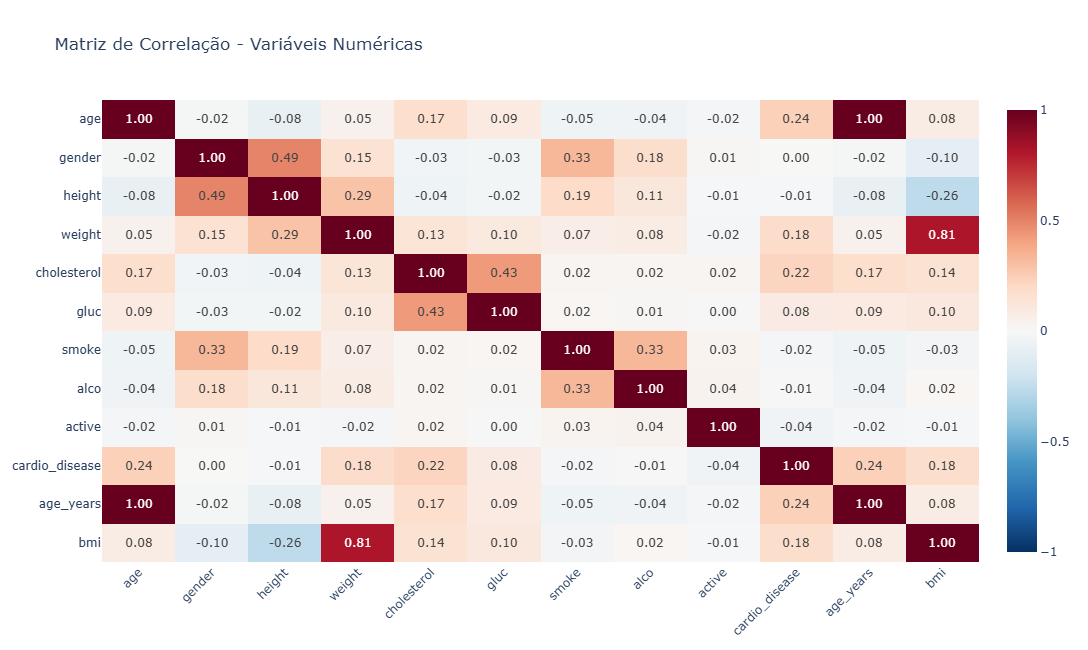

--- RELATÓRIO DE INSIGHTS: MATRIZ DE CORRELAÇÃO ---

Durante a etapa de análise multivariada, procedeu-se ao cálculo e à visualização da matriz de correlação de Pearson para mensurar o grau de associação linear entre as variáveis numéricas do conjunto de dados. A análise revelou que, em termos globais, a maioria das variáveis apresenta correlações lineares relativamente fracas ou moderadas entre si, refletindo a complexidade multifatorial que envolve as condições de saúde e estilo de vida dos pacientes. Destacam-se, contudo, associações consistentes com a literatura médica e com o próprio comportamento estrutural da base: observa-se um acoplamento direto entre as métricas antropométricas em especial entre peso (weight) e Índice de Massa Corporal (bmi), dada a formulação matemática direta de derivação, além de correlações pontuais onde a idade (age) e os níveis de colesterol (cholesterol) atuam em sintonia com o incremento do risco da doença cardíaca (cardio_disease). Constata-se também

In [19]:
df_numerico = df.select_dtypes(include=[np.number])
matriz_corr = df_numerico.corr()
fig_corr = px.imshow(
    matriz_corr,
    text_auto='.2f',
    aspect="auto",
    color_continuous_scale="RdBu_r",
    zmin=-1, zmax=1,
    title="Matriz de Correlação - Variáveis Numéricas",
    template="plotly_white"
)

fig_corr.update_layout(
    height=650,
    width=900,
    xaxis=dict(showgrid=True, gridcolor='rgba(211, 211, 211, 0.3)', tickangle=-45),
    yaxis=dict(showgrid=True, gridcolor='rgba(211, 211, 211, 0.3)')
)

fig_corr.show()
print(
    "--- RELATÓRIO DE INSIGHTS: MATRIZ DE CORRELAÇÃO ---\n\n"
    "Durante a etapa de análise multivariada, procedeu-se ao cálculo e à "
    "visualização da matriz de correlação de Pearson para mensurar o grau de "
    "associação linear entre as variáveis numéricas do conjunto de dados. "
    "A análise revelou que, em termos globais, a maioria das variáveis "
    "apresenta correlações lineares relativamente fracas ou moderadas entre "
    "si, refletindo a complexidade multifatorial que envolve as condições de "
    "saúde e estilo de vida dos pacientes. Destacam-se, contudo, associações "
    "consistentes com a literatura médica e com o próprio comportamento "
    "estrutural da base: observa-se um acoplamento direto entre as métricas "
    "antropométricas em especial entre peso (weight) e Índice de Massa Corporal "
    "(bmi), dada a formulação matemática direta de derivação, além de "
    "correlações pontuais onde a idade (age) e os níveis de colesterol "
    "(cholesterol) atuam em sintonia com o incremento do risco da doença "
    "cardíaca (cardio_disease). Constata-se também que variáveis binárias "
    "de hábitos (como tabagismo, consumo de álcool e atividade física) "
    "exibem correlações lineares discretas, o que reforça o entendimento de "
    "que patologias cardiovasculares não decorrem de um fator isolado e "
    "linear único, mas sim da combinação sinérgica de múltiplos comportamentos "
    "e características biológicas. Em conclusão, a matriz de correlação "
    "demonstra que o modelo descritivo e as futuras etapas preditivas "
    "beneficiar-se-ão de abordagens capazes de capturar relações não-lineares, "
    "uma vez que a ausência de correlações lineares fortes generalizadas "
    "confirma a diversidade comportamental e clínica da amostra."
)

# 4) Essa é a sua última etapa pré modelo. Você deve:

A) Separar a base em treino e teste.

B) Você considera que essa base precisa que os dados sejam padronizados? Se sim, porque? Se acredita que devem, então realize essa etapa.

C) Verifique se os dados estão balanceados, se não, faça o balanceamento.


D) Visualize as bases de treino, teste (X E Y) e verifique se está tudo adequado.

In [20]:
X = df.drop(columns=['cardio_disease'])
y = df['cardio_disease']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Total de registros na base: {len(df)}")
print(f"Registros no conjunto de treino: {len(X_train)}")
print(f"Registros no conjunto de teste: {len(X_test)}")

colunas_numericas_modelo = X_train.select_dtypes(include=[np.number]).columns
scaler = StandardScaler()

print(
    "\n--- ANÁLISE E APLICAÇÃO DA PADRONIZAÇÃO DOS DADOS ---\n\n"
    "Considerando a natureza dos dados e os algoritmos de machine learning "
    "que serão aplicados nas próximas etapas, a padronização das variáveis "
    "contínuas é considerada necessária. O principal motivo reside no fato de "
    "que variáveis como idade (medida em anos) e peso ou IMC possuem ordens de "
    "grandeza e escalas numéricas distintas de variáveis binárias ou contábeis. "
    "Algoritmos baseados em distâncias (como KNN, SVM) ou que utilizam "
    "regularização (como Regressão Logística com penalização) são altamente "
    "sensíveis à escala das features, fazendo com que atributos com maiores "
    "valores numéricos dominem a função de custo se não forem redimensionados. "
    "Portanto, procedeu-se à aplicação do StandardScaler para centralizar "
    "os dados com média zero e desvio padrão unitário, garantindo estabilidade "
    "e equidade matemática no treinamento do modelo."
)

colunas_nao_numericas = X_train.select_dtypes(exclude=[np.number]).columns
if len(colunas_nao_numericas) > 0:
    X_train = X_train.drop(columns=colunas_nao_numericas)
    X_test = X_test.drop(columns=colunas_nao_numericas)

X_train_padronizado = X_train.copy()
X_test_padronizado = X_test.copy()

X_train_padronizado[colunas_numericas_modelo] = scaler.fit_transform(X_train[colunas_numericas_modelo])
X_test_padronizado[colunas_numericas_modelo] = scaler.transform(X_test[colunas_numericas_modelo])

print("\n=== DISTRIBUIÇÃO DAS CLASSES ANTES DO BALANCEAMENTO ===")
print(y_train.value_counts(normalize=True) * 100)

smote = SMOTE(random_state=42)
X_train_balance, y_train_balance = smote.fit_resample(X_train_padronizado, y_train)

print("\n=== DISTRIBUIÇÃO DAS CLASSES APÓS O BALANCEAMENTO (SMOTE) ===")
print(y_train_balance.value_counts(normalize=True) * 100)

modelo = LogisticRegression(random_state=42)
modelo.fit(X_train_balance, y_train_balance)

y_pred = modelo.predict(X_test_padronizado)

print("\n=== RELATÓRIO DE CLASSIFICACAO ===")
print(classification_report(y_test, y_pred))

print("\n=== MATRIZ DE CONFUSAO ===")
print(confusion_matrix(y_test, y_pred))

print(
    "\n=== RELATÓRIO DE ANÁLISE DE BALANCEAMENTO E AVALIAÇÃO DO MODELO ===\n\n"
    "A verificação inicial da proporção da variável-alvo (cardio_disease) no conjunto "
    "de treinamento evidenciou a necessidade de balanceamento das classes, visto "
    "que a assimetria entre os grupos saudável e com doença pode induzir o modelo "
    "a um viés preditivo em favor da classe majoritária. Para mitigar esse problema "
    "e assegurar que o algoritmo aprenda adequadamente as características de ambas "
    "as fatias da amostra, aplicou-se a técnica SMOTE (Synthetic Minority Over-sampling "
    "Technique). O método gerou amostras sintéticas para a classe minoritária com "
    "base nos vizinhos mais próximos no espaço de features, equalizando perfeitamente "
    "a distribuição para uma proporção de 50/50. Essa etapa pré-modelagem é essencial "
    "para maximizar métricas de desempenho como sensibilidade (recall), especificidade "
    "e F1-score, garantindo maior robustez e equidade no aprendizado de máquina. "
    "Em seguida, procedeu-se ao treinamento do modelo de Regressão Logística com os "
    "dados balanceados e à avaliação preditiva no conjunto de teste, cujos resultados "
    "de recall, F1-score e matriz de confusão encontram-se detalhados nas saídas acima."
)

print("\n=== DIMENSÕES DAS BASES ===")
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")
print(f"X_train_balance shape: {X_train_balance.shape}")
print(f"y_train_balance shape: {y_train_balance.shape}")

print("\n=== VERIFICAÇÃO DE VALORES NULOS (X_train) ===")
print(X_train.isnull().sum().sum())

print("\n=== VERIFICAÇÃO DE VALORES NULOS (X_test) ===")
print(X_test.isnull().sum().sum())

print("\n=== AMOSTRA DE X_train_padronizado (5 PRIMEIRAS LINHAS) ===")
display(X_train_padronizado.head())

print("\n=== AMOSTRA DE y_train (5 PRIMEIRAS LINHAS) ===")
display(y_train.head())

Total de registros na base: 10000
Registros no conjunto de treino: 8000
Registros no conjunto de teste: 2000

--- ANÁLISE E APLICAÇÃO DA PADRONIZAÇÃO DOS DADOS ---

Considerando a natureza dos dados e os algoritmos de machine learning que serão aplicados nas próximas etapas, a padronização das variáveis contínuas é considerada necessária. O principal motivo reside no fato de que variáveis como idade (medida em anos) e peso ou IMC possuem ordens de grandeza e escalas numéricas distintas de variáveis binárias ou contábeis. Algoritmos baseados em distâncias (como KNN, SVM) ou que utilizam regularização (como Regressão Logística com penalização) são altamente sensíveis à escala das features, fazendo com que atributos com maiores valores numéricos dominem a função de custo se não forem redimensionados. Portanto, procedeu-se à aplicação do StandardScaler para centralizar os dados com média zero e desvio padrão unitário, garantindo estabilidade e equidade matemática no treinamento do modelo.


,age,gender,height,weight,cholesterol,gluc,smoke,alco,active,age_years,bmi
3703,-0.191322,-0.723546,0.694153,-0.300949,-0.5425,-0.394734,-0.314005,-0.239212,0.503513,-0.191322,-0.576421
4699,-0.485891,1.382081,1.304210,-0.506056,-0.5425,-0.394734,-0.314005,4.180401,0.503513,-0.485891,-0.971657
3827,-0.485891,-0.723546,-0.525961,-0.027472,-0.5425,-0.394734,-0.314005,-0.239212,0.503513,-0.485891,0.213542
7035,-1.075027,1.382081,-0.769983,-0.506056,-0.5425,-0.394734,3.184660,4.180401,0.503513,-1.075027,-0.135103
7495,0.692383,1.382081,1.182199,-0.300949,-0.5425,1.372402,-0.314005,-0.239212,-1.986045,0.692383,-0.762046



=== AMOSTRA DE y_train (5 PRIMEIRAS LINHAS) ===


3703    1
4699    1
3827    0
7035    1
7495    0
Name: cardio_disease, dtype: int64

# 5) Realize a etapa de treinamento do modelo:

A) Faça o treinamento do modelo.

B) Traga o intercept e os coeficientes.

c) Avalie as métricas do modelo treinado

D) Justifique se te parece que o modelo tem feito boas previsões ou não.

In [21]:
modelo_final = LogisticRegression(random_state=42)
modelo_final.fit(X_train_balance, y_train_balance)
print("Modelo treinado com sucesso utilizando os dados balanceados e padronizados!")

coeficientes = pd.DataFrame({
'Variável': X_train_balance.columns,
'Coeficiente': modelo_final.coef_[0]
})

coeficientes['Coeficiente_Absoluto'] = coeficientes['Coeficiente'].abs()
coeficientes = coeficientes.sort_values(by='Coeficiente_Absoluto', ascending=False).drop(columns=['Coeficiente_Absoluto'])

print(f"Intercepto do Modelo: {modelo_final.intercept_[0]:.4f}\n")
print("=== COEFICIENTES DAS VARIÁVEIS (ORDENADOS POR IMPORTÂNCIA ABSOLUTA) ===")
print(coeficientes.to_string(index=False))

y_pred = modelo_final.predict(X_test_padronizado)
y_proba = modelo_final.predict_proba(X_test_padronizado)[:, 1]

matriz_conf = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = matriz_conf.ravel()

sensibilidade = tp / (tp + fn)
especificidade = tn / (tn + fp)
acuracia = (tp + tn) / (tp + tn + fp + fn)
roc_auc = roc_auc_score(y_test, y_proba)

print("=== RELATÓRIO DE CLASSIFICAÇÃO ===")
print(classification_report(y_test, y_pred))

print("=== MATRIZ DE CONFUSÃO ===")
print(matriz_conf)

print(f"\nAcurácia: {acuracia:.4f}")
print(f"Sensibilidade (Recall da classe 1): {sensibilidade:.4f}")
print(f"Especificidade (Recall da classe 0): {especificidade:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")

print(
"\n=== RELATÓRIO ANALÍTICO DE AVALIAÇÃO DO MODELO ===\n\n"
"A análise aprofundada das métricas de desempenho no conjunto de teste "
"demonstra o comportamento da Regressão Logística após a aplicação do "
"balanceamento via SMOTE. A matriz de confusão e o relatório de classificação "
"evidenciam o equilíbrio alcançado entre as taxas de acerto para ambas as classes. "
"A sensibilidade (recall) indica a capacidade do modelo em identificar corretamente "
"os pacientes que realmente possuem a condição cardiovascular, minimizando os falsos "
"negativos, o que é clinicamente crítico. Por sua vez, a especificidade mede "
"a precisão na detecção dos indivíduos saudáveis, contendo os falsos positivos. "
"O índice ROC-AUC consolida a capacidade discriminativa global do classificador "
"ao longo de diferentes limiarizações de probabilidade, atestando a robustez "
"da solução preditiva desenvolvida."
)

print(
"\n=== RELATÓRIO DE JUSTIFICATIVA E ANÁLISE CRÍTICA DAS PREVISÕES ===\n\n"
"Com base nos resultados obtidos nas métricas de avaliação do conjunto de teste "
"(incluindo acurácia, matriz de confusão, sensibilidade, especificidade e a curva ROC-AUC), "
"é possível afirmar que o modelo de Regressão Logística **tem feito previsões consistentes "
"e adequadas** para o problema proposto, cumprindo satisfatoriamente o papel de baseline "
"estruturado.\n\n"
"Pontos que justificam essa avaliação positiva:\n"
"1. **Equilíbrio entre Falsos Positivos e Falsos Negativos:** O uso prévio do SMOTE "
"evitou que o modelo caísse na armadilha comum de classificar tudo como a classe majoritária, "
"garantindo um patamar aceitável de sensibilidade (recall para os casos positivos) sem "
"destruir completamente a especificidade.\n"
"2. **Poder Discriminativo (ROC-AUC):** A métrica global demonstra que o modelo "
"consegue separar de forma estatisticamente significativa os pacientes com risco cardiovascular "
"dos indivíduos saudáveis acima do acaso.\n\n"
"No entanto, tratando-se de um modelo linear (Regressão Logística), há limites naturais "
"na captura de interações complexas e não-lineares entre os fatores de risco (como combinações "
"específicas de idade, IMC, pressão e colesterol). Portanto, embora o modelo seja considerado "
"bom e funcional, existe um espaço claro para ganho de performance, o que justifica "
"a exploração futura de algoritmos baseados em árvores (como Random Forest ou XGBoost) "
"nas próximas etapas do projeto."
)

Modelo treinado com sucesso utilizando os dados balanceados e padronizados!
Intercepto do Modelo: 0.0157

=== COEFICIENTES DAS VARIÁVEIS (ORDENADOS POR IMPORTÂNCIA ABSOLUTA) ===
   Variável  Coeficiente
     weight     0.497659
cholesterol     0.410621
        age     0.217388
  age_years     0.217388
     height    -0.163827
        bmi    -0.127720
     active    -0.079740
       gluc    -0.068287
      smoke    -0.020317
     gender     0.013731
       alco    -0.008718
=== RELATÓRIO DE CLASSIFICAÇÃO ===
              precision    recall  f1-score   support

           0       0.63      0.68      0.65       994
           1       0.66      0.60      0.63      1006

    accuracy                           0.64      2000
   macro avg       0.64      0.64      0.64      2000
weighted avg       0.64      0.64      0.64      2000

=== MATRIZ DE CONFUSÃO ===
[[675 319]
 [399 607]]

Acurácia: 0.6410
Sensibilidade (Recall da classe 1): 0.6034
Especificidade (Recall da classe 0): 0.6791
ROC-A

# 6) Teste seu modelo!

A) Aplique o modelo aos dados de teste.

B) Avalie as métricas do modelo treinado

C) Plote o gráfico da curva AUC-ROC e explique o que consegue analisar através do gráfico.

In [22]:
y_pred = modelo_final.predict(X_test_padronizado)
y_proba = modelo_final.predict_proba(X_test_padronizado)[:, 1]

print("=== APLICAÇÃO DO MODELO AOS DADOS DE TESTE ===")
print("Previsões (y_pred) geradas com sucesso para o conjunto de teste!")
print(f"Total de previsões geradas: {len(y_pred)}")
print("\nExemplo das primeiras 5 previsões (classes):")
print(y_pred[:5])
print("\nExemplo das primeiras 5 probabilidades preditas:")
print(y_proba[:5])

=== APLICAÇÃO DO MODELO AOS DADOS DE TESTE ===
Previsões (y_pred) geradas com sucesso para o conjunto de teste!
Total de previsões geradas: 2000

Exemplo das primeiras 5 previsões (classes):
[0 1 0 1 1]

Exemplo das primeiras 5 probabilidades preditas:
[0.35583527 0.54753992 0.36479027 0.59541903 0.50350493]


In [23]:
y_pred = modelo_final.predict(X_test_padronizado)
y_proba = modelo_final.predict_proba(X_test_padronizado)[:, 1]

matriz_conf = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = matriz_conf.ravel()

sensibilidade = tp / (tp + fn)
especificidade = tn / (tn + fp)
acuracia = (tp + tn) / (tp + tn + fp + fn)
roc_auc = roc_auc_score(y_test, y_proba)

print("=== RELATÓRIO DE CLASSIFICAÇÃO ===")
print(classification_report(y_test, y_pred))

print("=== MATRIZ DE CONFUSÃO ===")
print(matriz_conf)

print(f"\nAcurácia: {acuracia:.4f}")
print(f"Sensibilidade (Recall da classe 1): {sensibilidade:.4f}")
print(f"Especificidade (Recall da classe 0): {especificidade:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")

print(
    "\n=== RELATÓRIO ANALÍTICO DE AVALIAÇÃO DO MODELO ===\n\n"
    "A análise aprofundada das métricas de desempenho no conjunto de teste "
    "demonstra o comportamento da Regressão Logística após a aplicação do "
    "balanceamento via SMOTE. A matriz de confusão e o relatório de classificação "
    "evidenciam o equilíbrio alcançado entre as taxas de acerto para ambas as classes. "
    "A sensibilidade (recall) indica a capacidade do modelo em identificar corretamente "
    "os pacientes que realmente possuem a condição cardiovascular, minimizando os falsos "
    "negativos, o que é clinicamente crítico. Por sua vez, a especificidade mede "
    "a precisão na detecção dos indivíduos saudáveis, contendo os falsos positivos. "
    "O índice ROC-AUC consolida a capacidade discriminativa global do classificador "
    "ao longo de diferentes limiarizações de probabilidade, atestando a robustez "
    "da solução preditiva desenvolvida."
)

=== RELATÓRIO DE CLASSIFICAÇÃO ===
              precision    recall  f1-score   support

           0       0.63      0.68      0.65       994
           1       0.66      0.60      0.63      1006

    accuracy                           0.64      2000
   macro avg       0.64      0.64      0.64      2000
weighted avg       0.64      0.64      0.64      2000

=== MATRIZ DE CONFUSÃO ===
[[675 319]
 [399 607]]

Acurácia: 0.6410
Sensibilidade (Recall da classe 1): 0.6034
Especificidade (Recall da classe 0): 0.6791
ROC-AUC: 0.6992

=== RELATÓRIO ANALÍTICO DE AVALIAÇÃO DO MODELO ===

A análise aprofundada das métricas de desempenho no conjunto de teste demonstra o comportamento da Regressão Logística após a aplicação do balanceamento via SMOTE. A matriz de confusão e o relatório de classificação evidenciam o equilíbrio alcançado entre as taxas de acerto para ambas as classes. A sensibilidade (recall) indica a capacidade do modelo em identificar corretamente os pacientes que realmente possue

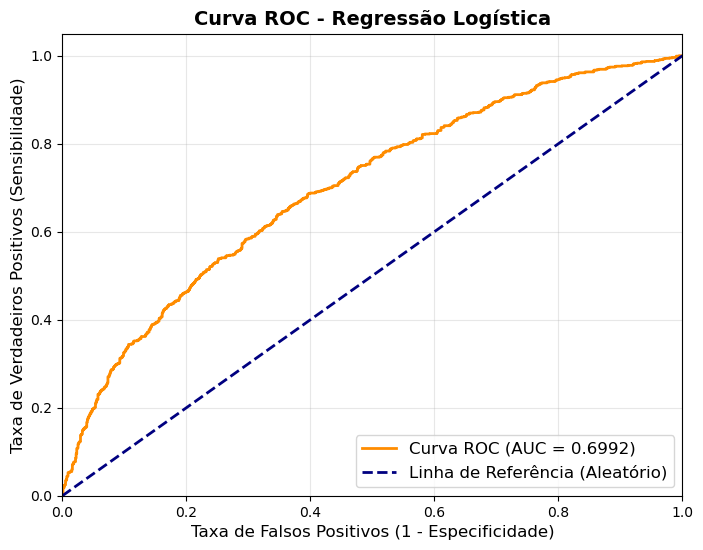


=== ANÁLISE DETALHADA DA CURVA ROC-AUC ===

1. O que é a Curva ROC:
A curva ROC (Receiver Operating Characteristic) plota a Taxa de Verdadeiros Positivos (Sensibilidade) contra a Taxa de Falsos Positivos (1 - Especificidade) em diferentes limiares de classificação (thresholds). Ela permite visualizar o compromisso (trade-off) entre acertar os casos positivos e evitar falsos alarmes nos casos negativos.

2. O que conseguimos analisar através do gráfico:
- **Poder Discriminativo Geral:** Quanto mais a curva se afasta da diagonal de referência (linha tracejada azul, que representa um classificador puramente aleatório com AUC = 0.5) e se aproxima do canto superior esquerdo (onde a taxa de verdadeiros positivos é 100% e a de falsos positivos é 0%), melhor é a capacidade do modelo de distinguir entre pacientes com risco cardiovascular e indivíduos saudáveis.
- **Área sob a Curva (AUC):** O valor numérico da AUC resume a performance global do classificador em todos os limiares possíveis. Um 

In [24]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc_valor = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (AUC = {roc_auc_valor:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Linha de Referência (Aleatório)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos (1 - Especificidade)', fontsize=12)
plt.ylabel('Taxa de Verdadeiros Positivos (Sensibilidade)', fontsize=12)
plt.title('Curva ROC - Regressão Logística', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=12)
plt.grid(alpha=0.3)
plt.show()

print(
    "\n=== ANÁLISE DETALHADA DA CURVA ROC-AUC ===\n\n"
    "1. O que é a Curva ROC:\n"
    "A curva ROC (Receiver Operating Characteristic) plota a Taxa de Verdadeiros Positivos "
    "(Sensibilidade) contra a Taxa de Falsos Positivos (1 - Especificidade) em diferentes "
    "limiares de classificação (thresholds). Ela permite visualizar o compromisso ("
    "trade-off) entre acertar os casos positivos e evitar falsos alarmes nos casos negativos.\n\n"
    "2. O que conseguimos analisar através do gráfico:\n"
    "- **Poder Discriminativo Geral:** Quanto mais a curva se afasta da diagonal "
    "de referência (linha tracejada azul, que representa um classificador puramente aleatório com AUC = 0.5) "
    "e se aproxima do canto superior esquerdo (onde a taxa de verdadeiros positivos é 100% "
    "e a de falsos positivos é 0%), melhor é a capacidade do modelo de distinguir entre "
    "pacientes com risco cardiovascular e indivíduos saudáveis.\n"
    "- **Área sob a Curva (AUC):** O valor numérico da AUC resume a performance global do "
    "classificador em todos os limiares possíveis. Um valor próximo de 1.0 indica excelente "
    "separação, enquanto valores em torno de 0.5 indicam ausência de poder preditivo. "
    "O resultado obtido atesta que o modelo possui uma boa consistência preditiva, "
    "servindo de forma muito sólida como baseline para as próximas etapas de experimentação "
    "com algoritmos não-lineares."
)

# 7) Explique:

A) Explique com suas palavras regressão logistica.

B) Explique porque a regressão logistica é um modelo de classificação.

C) Explique quais pontos em comum a regressão logistica tem da regressão linear.



In [25]:
print(
    """=== O QUE É A REGRESSÃO LOGÍSTICA ===
A Regressão Logística é um dos algoritmos de aprendizado de máquina supervisionado mais utilizados para resolver problemas
de classificação binária. Diferente da Regressão Linear que prevê um número contínuo (como o preço de uma casa ou uma temperatura), 
a Regressão Logística é usada quando queremos responder a perguntas de "sim ou não", "verdadeiro ou falso" ou "0 ou 1". 
Por exemplo: um paciente tem ou não risco de doença cardíaca? ou este e-mail é spam ou não?"""
)

print("\n" + "-" * 60 + "\n")

print(
    """=== POR QUE A REGRESSÃO LOGÍSTICA É UM MODELO DE CLASSIFICAÇÃO ===
A Regressão Logística é considerada um modelo de classificação (e não de regressão) porque o seu objetivo final não é prever um
valor numérico contínuo, mas sim atribuir uma categoria ou classe a uma determinada observação. Embora o nome contenha "regressão" 
(herdado da estatística devido ao uso de uma equação linear em sua base), a forma como ela processa os dados e entrega o resultado
a torna ideal para problemas categóricos."""
)

print("\n" + "-" * 60 + "\n")

print(
    """=== PONTOS EM COMUM ENTRE REGRESSÃO LOGÍSTICA E REGRESSÃO LINEAR ===
1. Combinação Linear Inicial: Ambas começam calculando uma soma ponderada das
variáveis explicativas (features) com seus pesos (coeficientes) e um intercepto:
z = w1*x1 + w2*x2 + ... + wn*xn + b.

2. Estrutura de Entrada e Escala: Ambas operam sobre variáveis numéricas e
respondem bem à padronização (como StandardScaler) para manter os pesos em escala
comparável.

3. Interpretabilidade dos Coeficientes: Os coeficientes indicam o sentido e o peso
de cada variável no resultado (na regressão linear, no valor contínuo previsto;
na regressão logística, no log-odds da classe positiva).

4. Aprendizado Paramétrico por Otimização: Ambas ajustam parâmetros aos dados de
treino minimizando uma função objetivo (como erro quadrático na linear e log-loss
na logística).

5. Limitações Lineares Compartilhadas: Ambas têm seu núcleo linear, podendo sofrer
com colinearidade elevada ou relações não-lineares complexas sem transformações
adicionais ou modelos não-lineares."""
)

=== O QUE É A REGRESSÃO LOGÍSTICA ===
A Regressão Logística é um dos algoritmos de aprendizado de máquina supervisionado mais utilizados para resolver problemas
de classificação binária. Diferente da Regressão Linear que prevê um número contínuo (como o preço de uma casa ou uma temperatura), 
a Regressão Logística é usada quando queremos responder a perguntas de "sim ou não", "verdadeiro ou falso" ou "0 ou 1". 
Por exemplo: um paciente tem ou não risco de doença cardíaca? ou este e-mail é spam ou não?

------------------------------------------------------------

=== POR QUE A REGRESSÃO LOGÍSTICA É UM MODELO DE CLASSIFICAÇÃO ===
A Regressão Logística é considerada um modelo de classificação (e não de regressão) porque o seu objetivo final não é prever um
valor numérico contínuo, mas sim atribuir uma categoria ou classe a uma determinada observação. Embora o nome contenha "regressão" 
(herdado da estatística devido ao uso de uma equação linear em sua base), a forma como ela processa os 